# Capítulo 3 · Actividad: limpieza de datos y outliers

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/riosinda/ml-course/blob/main/notebooks/exercises/chapter_03/02_actividad_limpieza_outliers.ipynb)

Vas a aplicar lo que viste en la notebook de clase `04_limpieza_y_outliers` a **tres datasets distintos**. Cada uno tiene problemas diferentes, igual que en la vida real.

### Antes de empezar

1. **Copia esta notebook a `workspace/`** y trabaja sobre la copia.
2. Si todavía no tienes los datos, descárgalos desde la raíz del repo:
   ```bash
   uv run python scripts/download_data.py
   ```

### Cómo trabajar

- Cada ejercicio tiene una celda `# Tu código aquí`. Añade todas las celdas que necesites.
- En las celdas ✍️ **justifica tus decisiones**: en limpieza de datos casi nunca hay una única respuesta correcta, pero siempre tiene que haber un motivo.
- Al terminar, ejecuta **Kernel → Restart & Run All**.

| Parte | Datos | Tema |
|---|---|---|
| A. Empleados | una tabla pequeña creada en la notebook | Limpieza estructural e imputación |
| B. Pingüinos | `data/penguins.csv` | Valores faltantes |
| C. Viviendas de California | `data/california_housing.csv` | Outliers |

In [185]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.impute import SimpleImputer

# Carpeta data/ en la raíz del repo: subimos de carpeta en carpeta hasta dar con pyproject.toml
raiz = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()), Path.cwd())
DATA_DIR = raiz / "data"

---
## Parte A · Empleados 👩‍💼

Recursos Humanos te pasa esta tabla, exportada a mano de varias hojas de cálculo. Ejecuta la celda para crearla.

In [186]:
empleados = pd.DataFrame({
    "nombre": ["Ana", "Luis", "Marta", "Luis", "Pedro", "Sofía", "Juan", "Elena",
               "Diego", "Carla", "Raúl", "Elena", "Iván", "Lucía"],
    "departamento": [" ventas", "IT", "it ", "IT", "Ventas", "RRHH", "rrhh", "VENTAS",
                     "It", "ventas ", "IT", "VENTAS", "RRHH", " Rrhh"],
    "edad": [34, np.nan, 29, np.nan, 45, 38, np.nan, 41, 27, np.nan, 52, 41, 31, 36],
    "salario": ["$35,000", "$52,000", "$48,500", "$52,000", "39000", "$41,200", "$37,800",
                "40500", "$47,000", "$36,900", "$61,000", "40500", "$39,900", "$42,300"],
    "fecha_ingreso": ["2019-03-15", "2020-07-01", "2021-01-10", "2020-07-01", "2015-09-30",
                      "2018-11-05", "2022-02-14", "2016-06-20", "2023-04-03", "2021-08-16",
                      "2012-01-09", "2016-06-20", "2019-10-21", "2017-05-02"],
})
empleados

,nombre,departamento,edad,salario,fecha_ingreso
0,Ana,ventas,34.0,"$35,000",2019-03-15
1,Luis,IT,NaN,"$52,000",2020-07-01
2,Marta,it,29.0,"$48,500",2021-01-10
3,Luis,IT,NaN,"$52,000",2020-07-01
4,Pedro,Ventas,45.0,39000,2015-09-30
5,Sofía,RRHH,38.0,"$41,200",2018-11-05
6,Juan,rrhh,NaN,"$37,800",2022-02-14
7,Elena,VENTAS,41.0,40500,2016-06-20
8,Diego,It,27.0,"$47,000",2023-04-03
9,Carla,ventas,NaN,"$36,900",2021-08-16


### Ejercicio 1 · Diagnóstico

Haz el diagnóstico de calidad de `empleados`: tipos de cada columna, valores faltantes, filas duplicadas y cómo están escritas las categorías.

In [187]:
# Tu código aquí
#primero checamos cuantos datos tenemos y como estan distribuidos
print(empleados.shape)
print(empleados.head())
print("\n")
#checamos los tipos de datos y relacionamos dependiendo de la caracteristica
print(empleados.info())
#checamos que edad tiene dos valores nulos
#tambien el salario es un tipo str en vez de un float64

(14, 5)
  nombre departamento  edad  salario fecha_ingreso
0    Ana       ventas  34.0  $35,000    2019-03-15
1   Luis           IT   NaN  $52,000    2020-07-01
2  Marta          it   29.0  $48,500    2021-01-10
3   Luis           IT   NaN  $52,000    2020-07-01
4  Pedro       Ventas  45.0    39000    2015-09-30


<class 'pandas.DataFrame'>
RangeIndex: 14 entries, 0 to 13
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   nombre         14 non-null     str    
 1   departamento   14 non-null     str    
 2   edad           10 non-null     float64
 3   salario        14 non-null     str    
 4   fecha_ingreso  14 non-null     str    
dtypes: float64(1), str(4)
memory usage: 692.0 bytes
None


In [188]:
#Se buscan cuantos nulos tienen las caracteristicas y el porcentaje que representan esos nulos.
print(empleados["edad"].isna())
pd.DataFrame({
    "nulos": empleados.isna().sum(),
    "porcentaje": (empleados.isna().mean() * 100).round(1),
})
#tenemos 28.6% que eso es un 1/4 de los datos totales, es importante revisarlo.

0     False
1      True
2     False
3      True
4     False
5     False
6      True
7     False
8     False
9      True
10    False
11    False
12    False
13    False
Name: edad, dtype: bool


,nulos,porcentaje
nombre,0,0.0
departamento,0,0.0
edad,4,28.6
salario,0,0.0
fecha_ingreso,0,0.0


In [189]:
#Conocer que filas son las que les falta datos
print(empleados[empleados.isna().any(axis=1)].head())
#En este caso encontramos una fila repetida y conocemos que datos faltan y en donde faltan.
print("\n")
#Buscamos si hay mas filas repetidas
print("Filas duplicadas:", empleados.duplicated().sum())
#Encontramos que solo hay dos filas que se duplican

  nombre departamento  edad  salario fecha_ingreso
1   Luis           IT   NaN  $52,000    2020-07-01
3   Luis           IT   NaN  $52,000    2020-07-01
6   Juan         rrhh   NaN  $37,800    2022-02-14
9  Carla      ventas    NaN  $36,900    2021-08-16


Filas duplicadas: 2


In [190]:
#Checamos si estan bien escritas las caracteristicas
for col in ["nombre", "departamento", "edad","salario","fecha_ingreso"]:
    print(empleados[col].value_counts(dropna=False), "\n")

#Se observa que en departamento hay muchos grupos iguales, solo escritos de diferente forma, se tiene que corregir eso.

nombre
Luis     2
Elena    2
Ana      1
Marta    1
Pedro    1
Sofía    1
Juan     1
Diego    1
Carla    1
Raúl     1
Iván     1
Lucía    1
Name: count, dtype: int64 

departamento
IT         3
RRHH       2
VENTAS     2
 ventas    1
it         1
Ventas     1
rrhh       1
It         1
ventas     1
 Rrhh      1
Name: count, dtype: int64 

edad
NaN     4
41.0    2
34.0    1
29.0    1
45.0    1
38.0    1
27.0    1
52.0    1
31.0    1
36.0    1
Name: count, dtype: int64 

salario
$52,000    2
40500      2
$35,000    1
$48,500    1
39000      1
$41,200    1
$37,800    1
$47,000    1
$36,900    1
$61,000    1
$39,900    1
$42,300    1
Name: count, dtype: int64 

fecha_ingreso
2020-07-01    2
2016-06-20    2
2019-03-15    1
2021-01-10    1
2015-09-30    1
2018-11-05    1
2022-02-14    1
2023-04-03    1
2021-08-16    1
2012-01-09    1
2019-10-21    1
2017-05-02    1
Name: count, dtype: int64 



✍️ **Pregunta:** haz una lista de todos los problemas que encontraste.

✍️ **Tu respuesta:** 

a)Tenemos 28.6% que eso es un 1/4 de los datos totales, es importante revisarlo.

b)Encontramos que solo hay dos filas que se duplican.

c)Se observa que en departamento hay muchos grupos iguales, solo escritos de diferente forma, se tiene que corregir eso.

d)El salario es un tipo str en vez de un float64

### Ejercicio 2 · Duplicados

Elimina las filas duplicadas. ¿Cuántas filas quedan?

In [191]:
# Tu código aquí
#Empezamos a limpiar los datos de la tabla
#Vamos a eliminar los duplicados en la tabla
empleados = empleados.drop_duplicates()
print("Filas tras eliminar duplicados:", len(empleados))
print("\n")

Filas tras eliminar duplicados: 12




### Ejercicio 3 · Texto inconsistente

Normaliza `departamento` para que queden **exactamente tres** valores: `Ventas`, `IT` y `RRHH` (las siglas, en mayúsculas).

In [192]:
# Tu código aquí
#Ahora vamos a cambiar a un mismo formato las palabras similiares
empleados["departamento"] = empleados["departamento"].str.strip().str.upper()
print(empleados["departamento"])
print("\n")

#Por ultimo, elimine 

0     VENTAS
1         IT
2         IT
4     VENTAS
5       RRHH
6       RRHH
7     VENTAS
8         IT
9     VENTAS
10        IT
12      RRHH
13      RRHH
Name: departamento, dtype: str




### Ejercicio 4 · Tipos de datos

a) Convierte `salario` a número. Ojo: no todos los valores tienen el mismo formato.

b) Convierte `fecha_ingreso` a fecha y crea la columna `año_ingreso`.

c) Comprueba los tipos con `dtypes`.

In [193]:
# Tu código aquí
#Comvertimos los datos str a int64, eliminamos los caracteres "$" y ","
empleados["salario"] = (empleados["salario"]
                .str.replace("$", "", regex=False)
                .str.replace(",", "", regex=False))
empleados["salario"] = pd.to_numeric(empleados["salario"])

empleados["fecha_venta"] = pd.to_datetime(empleados["fecha_ingreso"])
empleados.dtypes

nombre                      str
departamento                str
edad                    float64
salario                   int64
fecha_ingreso               str
fecha_venta      datetime64[us]
dtype: object

### Ejercicio 5 · Imputación

a) Crea una columna `edad_faltante` que indique qué empleados no tenían la edad.

b) Rellena la edad con la **mediana de su departamento**.

c) Comprueba que ya no quedan nulos y muestra la tabla final.

In [194]:
# Tu código aquí
#Creamos una columna nueva llamada "edad_faltantes" con valores booleanos donde aparecen Naan en la
#columna "edad"
empleados["edad_faltante"] = empleados["edad"].isna().astype(int)
#Se modifica la columna edad, para rellenar los espacios vacios con la mediana de edad del departamento correspondiente
empleados["edad"]=empleados["edad"].fillna(empleados.groupby("departamento")["edad"].transform("median"))
#se imprime el numero de Naan que se encuentren en la columna, si aparece 0 entonces la columna ya no tiene datos faltantes
print(f"Nulos:  {empleados["edad"].isna().sum()}")



Nulos:  0


✍️ **Pregunta:** ¿por qué la mediana del departamento y no la mediana de todos los empleados? ¿En qué caso daría igual?

✍️ **Tu respuesta:**  Debido a que seria mas exacto y congruente en el departamento, porque es donde se encuentran los empleados, y no generalizas datos.

---
## Parte B · Pingüinos 🐧 (valores faltantes)

El archivo `data/penguins.csv` tiene medidas de 344 pingüinos de tres especies. Columnas: `species`, `island`, `bill_length_mm`, `bill_depth_mm`, `flipper_length_mm`, `body_mass_g` y `sex`.

### Ejercicio 6 · Diagnóstico de faltantes

a) Carga los datos en `pinguinos`.

b) Calcula cuántos valores faltan en cada columna y qué porcentaje representan.

c) Muestra las filas que tienen algún valor faltante.

In [195]:
# Tu código aquí
penguins=pd.read_csv(DATA_DIR/"penguins.csv")
print(penguins.info())
#Los tipos de datos son correctos, y hacen falta algunos datos
print("\n")
print(penguins.isna().sum())
#Obtenemos que hacen falta bastantes datos en el sexo.
penguins[penguins["sex"].isna()]

<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    str    
dtypes: float64(4), str(3)
memory usage: 18.9 KB
None


species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
8,Adelie,Torgersen,34.1,18.1,193.0,3475.0,NaN
9,Adelie,Torgersen,42.0,20.2,190.0,4250.0,NaN
10,Adelie,Torgersen,37.8,17.1,186.0,3300.0,NaN
11,Adelie,Torgersen,37.8,17.3,180.0,3700.0,NaN
47,Adelie,Dream,37.5,18.9,179.0,2975.0,NaN
246,Gentoo,Biscoe,44.5,14.3,216.0,4100.0,NaN
286,Gentoo,Biscoe,46.2,14.4,214.0,4650.0,NaN
324,Gentoo,Biscoe,47.3,13.8,216.0,4725.0,NaN
336,Gentoo,Biscoe,44.5,15.7,217.0,4875.0,NaN


✍️ **Pregunta:** ¿ves algún patrón en las filas con faltantes? ¿Faltan los datos de forma parecida en todas?

✍️ **Tu respuesta:** Tienen en comun la especie y la isla. Hay algunos que no tienen nada de informacion.

### Ejercicio 7 · Eliminar o imputar

Hay pingüinos a los que les faltan **todas** las medidas. Elimínalos y comprueba cuántas filas quedan.

In [196]:
# Tu código aquí
penguins = penguins.dropna(subset=["bill_length_mm"])
penguins[penguins["sex"].isna()]

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
8,Adelie,Torgersen,34.1,18.1,193.0,3475.0,NaN
9,Adelie,Torgersen,42.0,20.2,190.0,4250.0,NaN
10,Adelie,Torgersen,37.8,17.1,186.0,3300.0,NaN
11,Adelie,Torgersen,37.8,17.3,180.0,3700.0,NaN
47,Adelie,Dream,37.5,18.9,179.0,2975.0,NaN
246,Gentoo,Biscoe,44.5,14.3,216.0,4100.0,NaN
286,Gentoo,Biscoe,46.2,14.4,214.0,4650.0,NaN
324,Gentoo,Biscoe,47.3,13.8,216.0,4725.0,NaN
336,Gentoo,Biscoe,44.5,15.7,217.0,4875.0,NaN


✍️ **Pregunta:** ¿por qué en este caso es mejor eliminar esas filas que imputarlas?

✍️ **Tu respuesta:** Por el tamaño de los datos, tenemos mas de 300 datos, entonces no afecta casi nada, al contrario de tenerlos que si afecta.

### Ejercicio 8 · Dos estrategias para el sexo

Compara dos formas de rellenar `sex`, cada una en una **copia** de `pinguinos`:

a) Con la **moda**.

b) Con una categoría nueva, `"desconocido"`.

Muestra `value_counts()` del resultado en cada caso.

In [197]:
# Tu código aquí
#creamos dos copias para el inciso a y b
penguins_one = penguins.copy()
penguins_two = penguins.copy()

#Rellenamos los valores que no conocemos con la moda del sexo que mas se repite de todos los pingüinos.
moda = penguins_one["sex"].mode()[0]
penguins_one["sex"] = penguins_one["sex"].fillna(moda)

penguins_two["desconocido"] = penguins_two["sex"].isna()
penguins_two["sex"] = penguins_two["sex"].fillna(moda)

print(penguins_one["sex"].value_counts())
print(penguins_two["sex"].value_counts())




sex
Male      177
Female    165
Name: count, dtype: int64
sex
Male      177
Female    165
Name: count, dtype: int64


✍️ **Pregunta:** ¿qué estrategia elegirías aquí y por qué? Fíjate en cuántos machos y hembras hay.

✍️ **Tu respuesta:** Eligiria la moda, debido a que en la tabla original, se tiene una similitud en cuanto a cuantos machos y hembras hay entre especies.

### Ejercicio 9 · Con scikit-learn

Usa `SimpleImputer` para rellenar `sex` con el valor más frecuente. ¿Qué valor aprendió? ¿Coincide con la moda del ejercicio 8?

In [198]:
# Tu código aquí
imputador = SimpleImputer(strategy="most_frequent")
imputador.fit(penguins)

print(penguins["sex"].value_counts())

sex
Male      168
Female    165
Name: count, dtype: int64


---
## Parte C · Viviendas de California 🏠 (outliers)

El archivo `data/california_housing.csv` viene del censo de California de 1990. **Cada fila es un distrito** (un barrio), no una vivienda:

| Columna | Significado |
|---|---|
| `MedInc` | ingreso mediano del distrito (en decenas de miles de $) |
| `HouseAge` | antigüedad mediana de las viviendas (años) |
| `AveRooms` | número medio de habitaciones por vivienda |
| `AveBedrms` | número medio de dormitorios por vivienda |
| `Population` | población del distrito |
| `AveOccup` | número medio de personas por vivienda |
| `Latitude`, `Longitude` | ubicación |
| `MedHouseVal` | valor mediano de las viviendas (en cientos de miles de $) |

### Ejercicio 10 · Primer vistazo

Carga los datos en `california` y muestra sus estadísticas descriptivas.

In [199]:
# Tu código aquí
california = pd.read_csv(DATA_DIR/"california_housing.csv")
california.info()
california.head()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [200]:
california["AveOccup"].value_counts()

AveOccup
3.000000    35
2.000000    18
2.500000    17
2.666667    16
2.333333    13
            ..
2.560606     1
3.122807     1
2.325635     1
2.123209     1
2.616981     1
Name: count, Length: 18841, dtype: int64

✍️ **Pregunta:** ¿en qué columnas el máximo está muy lejos del percentil 75%? ¿Te parece posible algún valor?

✍️ **Tu respuesta:** 

### Ejercicio 11 · Detección visual

Dibuja en una misma figura el boxplot de `AveRooms`, `AveOccup` y `Population`, cada uno en su propio gráfico.

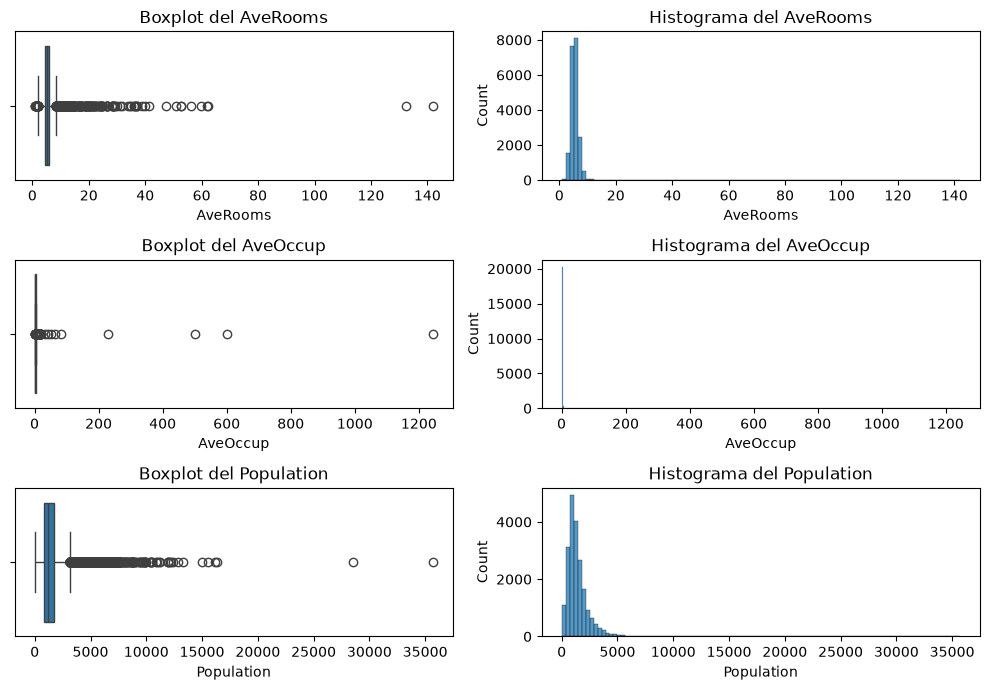

In [201]:
# Tu código aquí
fig1, axes = plt.subplots(3, 2,figsize=(10, 7))
sns.boxplot(x=california["AveRooms"], ax=axes[0,0])
axes[0,0].set_title("Boxplot del AveRooms")
sns.histplot(california["AveRooms"], bins=100, ax=axes[0,1])
axes[0,1].set_title("Histograma del AveRooms")
sns.boxplot(x=california["AveOccup"], ax=axes[1,0])
axes[1,0].set_title("Boxplot del AveOccup")
sns.histplot(x=california["AveOccup"],ax=axes[1,1])
axes[1,1].set_title("Histograma del AveOccup")
sns.boxplot(x=california["Population"], ax=axes[2,0])
axes[2,0].set_title("Boxplot del Population")
sns.histplot(x=california["Population"],bins=100,ax=axes[2,1])
axes[2,1].set_title("Histograma del Population")

plt.tight_layout()
plt.show()

### Ejercicio 12 · Z-score contra IQR

Para **cada columna** de `california`, cuenta cuántos outliers detecta el z-score ($|z| > 3$) y cuántos el IQR. Junta los resultados en un DataFrame con una fila por columna.

In [202]:
# Tu código aquí
z= (california-california.mean())/california.std()

print(f"Outliers por z-score:\n {(z.abs()>3).sum()}")

def limites_iqr(serie, k=1.5):
    """Devuelve los límites inferior y superior según la regla del IQR."""
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr


inf, sup = limites_iqr(california["AveRooms"])
print(f"Rango aceptable: [{inf:,.0f}, {sup:,.0f}]")
atipicos_iqr = california[(california["AveRooms"] < inf) | (california["AveRooms"] > sup)]
print("Outliers por IQR de AveRooms:", len(atipicos_iqr))

inf, sup = limites_iqr(california["AveBedrms"])
print(f"Rango aceptable: [{inf:,.0f}, {sup:,.0f}]")
atipicos_iqr = california[(california["AveBedrms"] < inf) | (california["AveBedrms"] > sup)]
print("Outliers por IQR de AveBedrms:", len(atipicos_iqr))

inf, sup = limites_iqr(california["Population"])
print(f"Rango aceptable: [{inf:,.0f}, {sup:,.0f}]")
atipicos_iqr = california[(california["Population"] < inf) | (california["Population"] > sup)]
print("Outliers por IQR de Population:", len(atipicos_iqr))

inf, sup = limites_iqr(california["AveOccup"])
print(f"Rango aceptable: [{inf:,.0f}, {sup:,.0f}]")
atipicos_iqr = california[(california["AveOccup"] < inf) | (california["AveOccup"] > sup)]
print("Outliers por IQR de AveOccup:", len(atipicos_iqr))




Outliers por z-score:
 MedInc         345
HouseAge         0
AveRooms       133
AveBedrms      145
Population     342
AveOccup         8
Latitude         0
Longitude        0
MedHouseVal      0
dtype: int64
Rango aceptable: [2, 8]
Outliers por IQR de AveRooms: 511
Rango aceptable: [1, 1]
Outliers por IQR de AveBedrms: 1424
Rango aceptable: [-620, 3,132]
Outliers por IQR de Population: 1196
Rango aceptable: [1, 5]
Outliers por IQR de AveOccup: 711


✍️ **Pregunta:** en `AveOccup`, ¿por qué el z-score detecta tan pocos outliers y el IQR tantos? ¿Cuál de los dos números te parece más razonable?

✍️ **Tu respuesta:** Porque el z-score esta relacionado con la media y la desviacio. Entonces toma los valores atipicos para el calculo de estos dos, afectando el umbral de donde si puede haber un dato tipico o no. Me pareece bien el segundo.

### Ejercicio 13 · Criterio de negocio

`AveOccup` es el número medio de personas que viven en cada vivienda del distrito.

a) Muestra los 5 distritos con mayor `AveOccup`.

b) Decide un **umbral razonable** por encima del cual el valor no tiene sentido, y elimina esos distritos. ¿Cuántos eliminaste?

In [203]:
# Tu código aquí
california.sort_values("AveOccup",ascending=False).head(5)

#Hay bastantes anomalias como el hecho de que vivan 1243 en una vivienda.
#En este caso el umbral seria de 1 persona hasta 12 personas.

errores_sup = (california["AveOccup"]>12)
print(f"Errores:{errores_sup.sum()}")
california = california[~errores_sup]

errores_inf = california["AveOccup"]<1
print(f"Errores: {errores_inf}")
california = california[~errores_inf]

inf, sup = limites_iqr(california["AveOccup"])
print(f"Rango aceptable: [{inf:,.0f}, {sup:,.0f}]")
atipicos_iqr = california[(california["AveOccup"] < inf) | (california["AveOccup"] > sup)]
print("Outliers por IQR de AveOccup:", len(atipicos_iqr))



Errores:32
Errores: 0        False
1        False
2        False
3        False
4        False
         ...  
20635    False
20636    False
20637    False
20638    False
20639    False
Name: AveOccup, Length: 20608, dtype: bool
Rango aceptable: [1, 5]
Outliers por IQR de AveOccup: 684


✍️ **Pregunta:** ¿qué umbral elegiste y por qué?

✍️ **Tu respuesta:** El umbral es de 1 a 12 personas, debido a que en una casa no pueden vivir demasiadas personas y mas debido a la media de los cuartos y baños.

### Ejercicio 15 · Un caso raro

Muestra los 5 valores más frecuentes de `MedHouseVal`.

In [208]:
# Tu código aquí
print(california["MedHouseVal"].value_counts())

MedHouseVal
5.00001    961
1.37500    121
1.62500    112
1.12500    103
1.87500     92
          ... 
4.22900      1
3.49400      1
4.25800      1
2.00700      1
0.47000      1
Name: count, Length: 3842, dtype: int64


✍️ **Pregunta:** ¿qué crees que pasó con el valor más repetido? ¿Es un outlier? ¿Qué problema podría causarle a un modelo que intente predecir el valor de las viviendas?

✍️ **Tu respuesta:** 